=== UPLOAD YOUR CSV FILE ===


Saving ev.csv to ev (2).csv

Successfully loaded 'ev (2).csv' (299,705 records)
Using County Column: 'County' | Type Column: 'Electric Vehicle Type'

--- TOP 10 COUNTIES: BEV vs PHEV COUNTS ---
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
County                                                  
Benton                                           3438   
Clark                                           14523   
King                                           119449   
Kitsap                                           7993   
Pierce                                          19721   
Skagit                                           2791   
Snohomish                                       31906   
Spokane                                          6435   
Thurston                                         8510   
Whatcom                                          5819   

Electric Vehicle Type  Plug-in Hybrid Electric Vehicle (PHEV)  
County                                                   

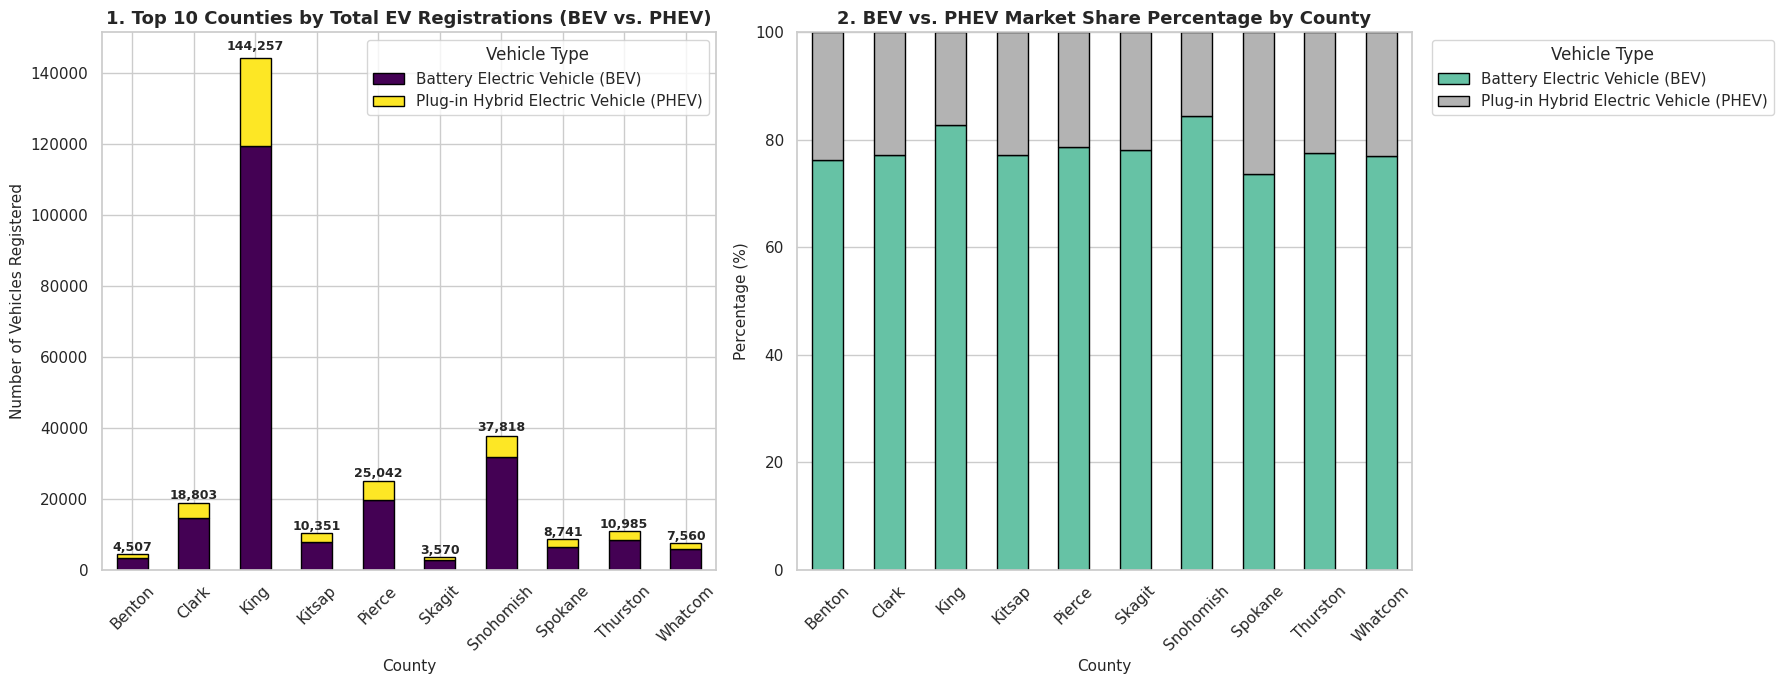


--- SUMMARY METRICS BY TOP COUNTY ---
Largest EV Market: King County (144,257 total EVs)
 -> BEV Share: 82.8%
 -> PHEV Share: 17.2%


In [ ]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Set global plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 8)
plt.rcParams["figure.dpi"] = 100

print("=== UPLOAD YOUR CSV FILE ===")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded! Please re-run the cell and upload your CSV file.")

filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Strip whitespace from columns
df.columns = df.columns.str.strip()

# Helper function to dynamically locate target columns
def find_col(possible_names, dataframe):
    for name in possible_names:
        for col in dataframe.columns:
            if name.lower() in col.lower():
                return col
    return None

col_county = find_col(["County"], df)
col_type = find_col(["Electric Vehicle Type", "EV Type"], df)

if col_county is None or col_type is None:
    raise KeyError(f"Could not map required columns. Found County: '{col_county}', Type: '{col_type}'.")

print(f"\nSuccessfully loaded '{filename}' ({len(df):,} records)")
print(f"Using County Column: '{col_county}' | Type Column: '{col_type}'")

# Clean missing values
df[col_county] = df[col_county].fillna("Unknown")

# Create Cross-Tabulation (Top 10 Counties by EV Count)
top_counties = df[col_county].value_counts().head(10).index
df_top = df[df[col_county].isin(top_counties)]

county_ct = pd.crosstab(df_top[col_county], df_top[col_type])

# Calculate Percentage Share Crosstab
county_pct = county_ct.div(county_ct.sum(axis=1), axis=0) * 100

print("\n--- TOP 10 COUNTIES: BEV vs PHEV COUNTS ---")
print(county_ct)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Absolute Counts (Stacked Bar Chart)
county_ct.plot(kind="bar", stacked=True, ax=ax1, colormap="viridis", edgecolor="black")
ax1.set_title("1. Top 10 Counties by Total EV Registrations (BEV vs. PHEV)", fontsize=13, fontweight="bold")
ax1.set_xlabel("County", fontsize=11)
ax1.set_ylabel("Number of Vehicles Registered", fontsize=11)
ax1.tick_params(axis="x", rotation=45)
ax1.legend(title="Vehicle Type")

# Annotate total values on top of bar charts
for i, county in enumerate(county_ct.index):
    total = county_ct.loc[county].sum()
    ax1.text(i, total + (total * 0.01), f"{total:,}", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Plot 2: Relative Share Breakdown (100% Stacked Bar Chart)
county_pct.plot(kind="bar", stacked=True, ax=ax2, colormap="Set2", edgecolor="black")
ax2.set_title("2. BEV vs. PHEV Market Share Percentage by County", fontsize=13, fontweight="bold")
ax2.set_xlabel("County", fontsize=11)
ax2.set_ylabel("Percentage (%)", fontsize=11)
ax2.tick_params(axis="x", rotation=45)
ax2.set_ylim(0, 100)
ax2.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

print("\n--- SUMMARY METRICS BY TOP COUNTY ---")
top_county_name = county_ct.sum(axis=1).idxmax()
top_county_bev = county_pct.loc[top_county_name].filter(like="Battery").values[0]
top_county_phev = county_pct.loc[top_county_name].filter(like="Plug-in").values[0]

print(f"Largest EV Market: {top_county_name} County ({county_ct.loc[top_county_name].sum():,} total EVs)")
print(f" -> BEV Share: {top_county_bev:.1f}%")
print(f" -> PHEV Share: {top_county_phev:.1f}%")